# Waveguide: first simulation

Start here for the 1D model. One atom is fixed at the origin; no geometry database is needed. Edit the photon, atom and time parameters, then run all cells. Atomic amplitudes have shape (time, 1).

**Setup:** from the repository root, run `conda env create -f environment.yml` then `conda activate single-photon-renorm`, then `jupyter lab`. Select that Python environment as the kernel. The first cell also supports running directly from the checkout.

**How to use:** run cells from top to bottom. Parameters are grouped before the simulation or plotting cells. Figures display inline; `SAVE_FIGURES=False` prevents overwriting exported PDFs. Units: ħ = c = 1. See `guide_utilisation.pdf` at the repository root for notation and the calibration workflow.


<h1> Use of the Experiment class </h1>

In [ ]:
# Run from the repository root or any of its subdirectories.
import sys
from pathlib import Path
project_root = next((p for p in (Path.cwd().resolve(), *Path.cwd().resolve().parents)
                     if (p / "src" / "experiment.py").is_file()), None)
if project_root is None:
    raise FileNotFoundError("Open Jupyter inside the single_photon_code checkout; see README.md.")
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))
benchmark_root = project_root / "waveguide_model"
setup_root = project_root / "2d_setup"

SAVE_FIGURES = False  # Set True to export the figures to results/fig.

#General imports
resol = 300
import matplotlib.pyplot as plt

plt.rcParams.update({
    "text.usetex": True,
    "font.family": "serif",
    "axes.linewidth": 0.7,
    "xtick.major.width": 0.6,
    "ytick.major.width": 0.6,
})

import numpy as np


#Local imports
from waveguide_model.setup import make_waveguide_config
from src import Experiment
from waveguide_model.bare_param import get_bare_parameters

<h2> Generate an initial configutation </h1>

The initial configuration is as follows:
- Gaussian photonic wave packet $(p_0, \sigma_p, x_0)$
- Physical cavity parameters $(\omega_A, \gamma_A, L)$
- Time evolution $(T, dt)$
- Cutoffs $(\Omega_{\mathrm{min}}, \Omega_{\mathrm{max}})$

In [11]:
L = 50

param_photon = {'p_init': 10*np.pi, 'sigma_p': 0.05*np.pi, 'x_init': -L/4}

Omega_A = 10*np.pi
gamma_A = np.pi

cutoffs = {'Omega_min': 5*np.pi, 'Omega_max': 13*np.pi}
Omega_0, gamma_0 = get_bare_parameters(Omega_A, gamma_A, cutoffs, correction=True)
param_cavity = {'Omega_0': Omega_0, 'gamma_0': gamma_0, 'L': L}

param_time_evol = {'T': 25, 'dt': 0.01}

<h2> Run an experiment </h2>

In [12]:
config = make_waveguide_config(photon=param_photon,
                          L=L, Omega_0=Omega_0, gamma_0=gamma_0,
                          time=param_time_evol,
                          cutoffs=cutoffs)

scattering_experiment = Experiment(config)
c_array, b_array = scattering_experiment.propagate_state(progress=True)

#Check eventual messages
messages = scattering_experiment.get_messages()

  0%|          | 0/2500 [00:00<?, ?it/s]

<h2> Visualize excitation numbers </h2>

Get the observables and generate a time array for the figure

In [13]:
time_array = scattering_experiment.times
#Compute observables
observables = scattering_experiment.compute_observables()
An_array, P1n_array, P2n_array = observables.atomic_population, observables.forward, observables.backward
#Check eventual messages
messages = scattering_experiment.get_messages()

#Print final reflection and transmission
print(f"Final reflection: {P2n_array[-1]:.4f}")
print(f"Final transmission: {P1n_array[-1]:.4f}")

Final reflection: 0.9901
Final transmission: 0.0098


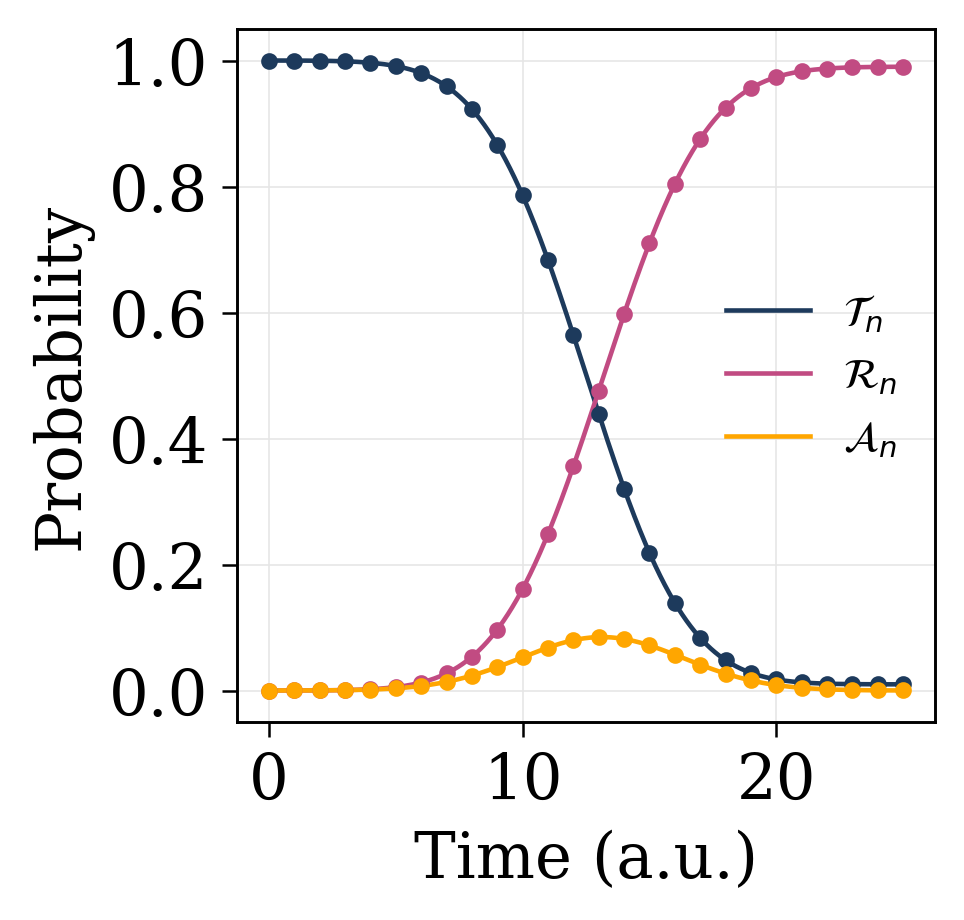

In [14]:
# Font sizes in points for this figure; edit these values directly.
plt.rcParams.update({
    "font.size": 9,
    "axes.labelsize": 9,
    "axes.titlesize": 9,
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
    "legend.fontsize": 9,
    "legend.title_fontsize": 9,
})

fig, ax = plt.subplots(figsize=(3, 3), dpi=300)

step_marker = 100  
color_Tn = '#1d3a5c'     
color_Rn = '#c14b82'      
color_atom = '#ffa600'

# ---- courbes lisses ----
ax.plot(time_array, P1n_array , '-', color=color_Tn, lw=1.1, label=r'$\mathcal{T}_n$')
ax.plot(time_array, P2n_array, '-', color=color_Rn, lw=1.1, label=r'$\mathcal{R}_n$')
ax.plot(time_array, An_array, '-', color=color_atom, lw=1.1, label=r'$\mathcal{A}_n$')

# ---- marqueurs discrets tous les N points ----
ax.plot(time_array[::step_marker], P1n_array[::step_marker], 'o', ms=3, color=color_Tn)
ax.plot(time_array[::step_marker], P2n_array[::step_marker], 'o', ms=3, color=color_Rn)
ax.plot(time_array[::step_marker], An_array[::step_marker], 'o', ms=3, color=color_atom)

# Labels, limites et grille
ax.set_xlabel(r'\textbf{Time (a.u.)}', fontsize=9)
ax.set_ylabel(r'\textbf{Probability}', fontsize=9)
#ax.set_xticks(np.array([0, 10, 20, 30, 40, 50]))
#ax.set_ylim(-0.05, 1.05)
ax.grid(color='0.9', linestyle='-', linewidth=0.4)

# Légende sobre
ax.legend(prop={'size': 9}, loc="center right", frameon=False)

#font size
for item in [ax.xaxis.label, ax.yaxis.label]:
    item.set_fontsize(9)

for item in (ax.get_xticklabels() + ax.get_yticklabels()):
    item.set_fontsize(9)

#plt.savefig(str(benchmark_root / "results" / "fig" / "single_photon_example_1.25omega0.pdf"), bbox_inches="tight")
plt.show()